In [30]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
rfm = pd.read_csv("../data/rfm.csv")

In [4]:
rfm_log = rfm[["Frequency","Recency","Monetary"]].map(np.log1p)
features = ["Recency", "Frequency", "Monetary"]
X_rfm = rfm_log[features]
X_scaled = StandardScaler().fit_transform(X=X_rfm)
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=rfm.index
)
X_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,-8.025955e-17,1.000115,-2.341296,-0.661361,0.089926,0.844792,1.564198
Frequency,4338.0,-8.189750e-18,1.000115,-0.955214,-0.955214,-0.361583,0.653237,5.858535
Monetary,4338.0,-3.472454e-16,1.000115,-3.997811,-0.683580,-0.065109,0.657218,4.732381


In [5]:
silhouette_scores = []
inertias = []
for k in range(2,10):
    kmeans = KMeans(n_clusters=k,random_state=42,init="k-means++")
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled,labels,random_state=42)
    )

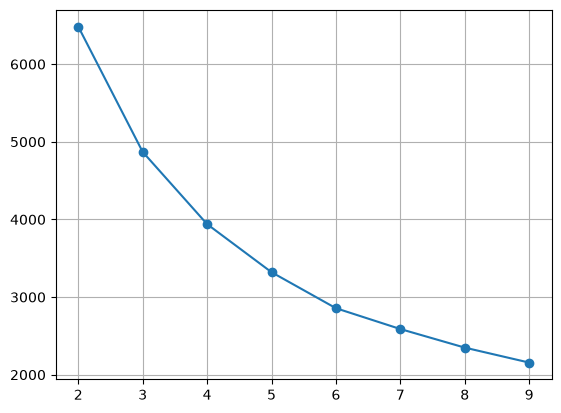

In [6]:
plt.plot(range(2,10),inertias,marker="o")
plt.grid()

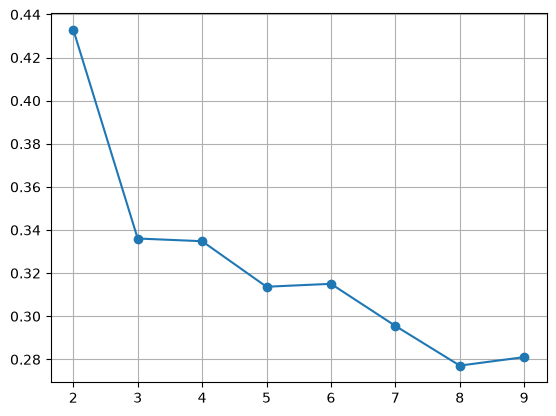

In [7]:
plt.plot(range(2,10),silhouette_scores,marker="o")
plt.grid()

In [28]:
kmeans = KMeans(n_clusters=3,init="k-means++")
rfm["Cluster"] = kmeans.fit_predict(X_scaled)
rfm[["Recency","Frequency","Monetary","Cluster"]].groupby("Cluster").describe().T

Cluster                     0            1              2
Recency   count   1689.000000  1923.000000     726.000000
          mean      44.620485   163.999480      14.721763
          std       44.746652   105.906652      21.982494
          min        1.000000     4.000000       1.000000
          25%       15.000000    65.500000       3.000000
          50%       30.000000   155.000000       9.000000
          75%       60.000000   253.000000      18.000000
          max      366.000000   374.000000     372.000000
Frequency count   1689.000000  1923.000000     726.000000
          mean       3.509769     1.357254      13.765840
          std        1.628408     0.651408      15.265927
          min        1.000000     1.000000       2.000000
          25%        2.000000     1.000000       7.000000
          50%        3.000000     1.000000      10.000000
          75%        4.000000     2.000000      15.000000
          max       12.000000     6.000000     209.000000
Monetary  count   1689.000000  1923.000000     726.000000
          mean    1374.498729   363.266152    8081.432135
          std     2541.925653   296.111952   20558.319777
          min      102.450000     3.750000     801.120000
          25%      644.950000   165.025000    2469.335000
          50%     1016.140000   299.340000    3783.990000
          75%     1611.590000   458.720000    6413.337500
          max    77183.600000  3096.000000  280206.020000

<Axes: xlabel='PC1', ylabel='PC2'>

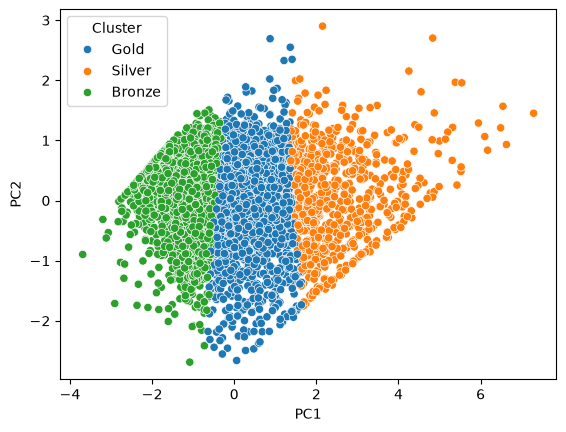

In [39]:
pca = PCA(n_components=2)
pca_features = pd.DataFrame(
    pca.fit_transform(X_scaled),
    columns=["PC1","PC2"]
)
pca_features["Cluster"] = rfm["Cluster"]
sns.scatterplot(
    data=pca_features,
    x="PC1",
    y="PC2",
    hue="Cluster")

In [29]:
labels = {
    0:"Gold",
    1:"Bronze",
    2:"Silver"
}
rfm["Cluster"] = rfm["Cluster"].map(labels)

In [40]:
rfm.to_csv("../data/clients_rfm.csv")